# 11_ROCOv2_Trust_Score

**Purpose:** Synthesize Notebooks 08 and 09's trustworthiness signals into
a single per-prediction Trust Score for the Proposed VLM, then validate
that it actually correlates with prediction correctness — a trust score
that hasn't been checked against ground truth isn't demonstrated to mean
anything.

### Methodology (confirmed, not assumed)
- **Scope:** Proposed VLM only, on the same (sample, label) pairs Notebook
  09 already analyzed (500 Test-final samples x 18 labels) — reusing that
  artifact directly rather than re-running counterfactual search.
- **No model is loaded and no inference is re-run.** This notebook only
  reads three existing artifacts (08's per-label conformal thresholds,
  09's per-sample counterfactual distances/probabilities, the label
  taxonomy) and combines them arithmetically.
- **Composite formula**, per (sample, label):
  - *Conformal component* — re-derive the LAC prediction-set size from
    08's saved `q̂` and 09's saved probability (same formula as 08, not
    re-calibrated): singleton set (decisive) → 1.0, both-included set
    (ambiguous) → 0.0, empty set (a rare LAC edge case) → 0.5.
  - *Counterfactual component* — 09's counterfactual distance, min-max
    normalized across the analyzed sample (larger distance from the
    decision boundary → higher trust).
  - **Trust Score = 0.5 x conformal component + 0.5 x counterfactual
    component** (equal weighting, explicit and adjustable, not hidden).
- **Validation:** bin predictions by Trust Score and check whether
  higher-trust bins actually have higher empirical accuracy. If they
  don't, that's reported as a real, negative finding — not hidden.

### Inputs
- `Prepared/ConformalPrediction/conformal_config.json` (08 — per-label
  `q̂` for the Proposed VLM).
- `Prepared/CounterfactualExplanations/counterfactual_distance_per_label_sample.csv`
  (09 — per-sample-label probabilities and counterfactual distances).
- `Prepared/label_mapping.json`.

### Outputs
Under `Prepared/TrustScore/`: full per-(sample, label) trust score table,
per-label summary, validation results/figure, config, reproducibility
record, manifest.

### Non-goals
No new model training or inference. No modification of any previous
notebook, model, or artifact.

In [ ]:
# ============================================================
# CELL 1 — CONFIGURATION, PATHS, AND REPRODUCIBILITY
# ============================================================

import sys
import json
import platform
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"

TRUST_DIR = PREPARED_DIR / "TrustScore"
FIG_DIR = TRUST_DIR / "figures"
for d in [TRUST_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

LABEL_MAPPING_PATH = PREPARED_DIR / "label_mapping.json"
CONFORMAL_CONFIG_PATH = PREPARED_DIR / "ConformalPrediction" / "conformal_config.json"
COUNTERFACTUAL_RESULTS_PATH = (
    PREPARED_DIR / "CounterfactualExplanations" / "counterfactual_distance_per_label_sample.csv"
)

TRUST_SCORES_PATH = TRUST_DIR / "trust_scores_per_sample_label.csv"
TRUST_SUMMARY_PATH = TRUST_DIR / "trust_score_per_label_summary.csv"
VALIDATION_PATH = TRUST_DIR / "trust_score_validation_bins.csv"
TRUST_FIGURE_PDF = FIG_DIR / "trust_score_by_label.pdf"
TRUST_FIGURE_PNG = FIG_DIR / "trust_score_by_label_300dpi.png"
VALIDATION_FIGURE_PDF = FIG_DIR / "trust_score_validation.pdf"
VALIDATION_FIGURE_PNG = FIG_DIR / "trust_score_validation_300dpi.png"
TRUST_CONFIG_PATH = TRUST_DIR / "trust_score_config.json"
REPRODUCIBILITY_PATH = TRUST_DIR / "reproducibility.json"
MANIFEST_PATH = TRUST_DIR / "artifact_manifest.json"

ALLOW_OVERWRITE = False

def safe_save_json(path, obj, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    print("Saved:", path)

def safe_save_csv(path, df, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    df.to_csv(path, index=False)
    print("Saved:", path)

SEED = 42
CONFORMAL_WEIGHT = 0.5
COUNTERFACTUAL_WEIGHT = 0.5
N_VALIDATION_BINS = 5

print("=" * 80)
print("NOTEBOOK 11 — TRUST SCORE")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("TRUST_DIR:", TRUST_DIR)
print(f"Weights: conformal={CONFORMAL_WEIGHT}, counterfactual={COUNTERFACTUAL_WEIGHT}")


Mounted at /content/drive
Google Drive available.
NOTEBOOK 11 — TRUST SCORE
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
TRUST_DIR: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore
Weights: conformal=0.5, counterfactual=0.5


## 1. Verify required inputs

In [ ]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "label_mapping.json": LABEL_MAPPING_PATH,
    "conformal_config.json": CONFORMAL_CONFIG_PATH,
    "counterfactual_distance_per_label_sample.csv": COUNTERFACTUAL_RESULTS_PATH,
}
missing_inputs = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]
if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 11 input artifacts are missing:\n\n" + "\n".join(missing_inputs)
        + "\n\nRun 02, 08, and 09 first."
    )

print("PASS — Required Notebook 02/08/09 artifacts exist.")
for name, path in required_inputs.items():
    print(f"{name:55s}: {path}")


PASS — Required Notebook 02/08/09 artifacts exist.
label_mapping.json                                     : /content/drive/MyDrive/ROCOv2/Prepared/label_mapping.json
conformal_config.json                                  : /content/drive/MyDrive/ROCOv2/Prepared/ConformalPrediction/conformal_config.json
counterfactual_distance_per_label_sample.csv           : /content/drive/MyDrive/ROCOv2/Prepared/CounterfactualExplanations/counterfactual_distance_per_label_sample.csv


## 2. Load label taxonomy, conformal thresholds, and counterfactual results

The per-label `q̂` values are the Proposed VLM's, read directly from
Notebook 08's saved config — not recalibrated here.

In [ ]:
# ============================================================
# CELL 3 — LOAD LABEL MAPPING, Q-HAT, AND COUNTERFACTUAL RESULTS
# ============================================================

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)

# label_mapping.json maps CUI -> column index, not CUI -> name; canonical
# names come from the same fixed lookup used in every prior notebook.
CANONICAL_LABEL_NAMES = {
    "C0000726": "Abdomen", "C0002978": "Angiogram", "C0006141": "Breast",
    "C0023216": "Lower Extremity", "C0024485": "Magnetic Resonance Imaging",
    "C0030797": "Pelvis", "C0032743": "Positron-Emission Tomography",
    "C0037303": "Bone structure of cranium", "C0037949": "Vertebral column",
    "C0040405": "X-Ray Computed Tomography", "C0041618": "Ultrasonography",
    "C0205106": "Transverse", "C0205129": "Sagittal", "C0817096": "Chest",
    "C1140618": "Upper Extremity", "C1306645": "Plain x-ray",
    "C1996865": "Postero-Anterior", "C1999039": "Anterior-Posterior",
}
LABEL_NAMES = [
    CANONICAL_LABEL_NAMES.get(cui, cui)
    for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])
]
N_LABELS = len(LABEL_NAMES)
assert N_LABELS == 18, "Authoritative label_mapping.json must contain exactly 18 labels."

with open(CONFORMAL_CONFIG_PATH, "r", encoding="utf-8") as f:
    conformal_config = json.load(f)

if "proposed_vlm" not in conformal_config["per_label_qhat"]:
    raise KeyError(
        "conformal_config.json does not contain per-label q-hat values for "
        "'proposed_vlm'. Re-run Notebook 08 if this key has changed."
    )
qhat_per_label = conformal_config["per_label_qhat"]["proposed_vlm"]

counterfactual_df = pd.read_csv(COUNTERFACTUAL_RESULTS_PATH)

print(f"Label taxonomy: {N_LABELS} labels.")
print(f"Loaded q-hat for {len(qhat_per_label)} labels (Proposed VLM, from Notebook 08).")
print(f"Loaded counterfactual results: {len(counterfactual_df):,} (sample x label) rows (from Notebook 09).")


Label taxonomy: 18 labels.
Loaded q-hat for 18 labels (Proposed VLM, from Notebook 08).
Loaded counterfactual results: 9,000 (sample x label) rows (from Notebook 09).


## 3. Re-derive conformal prediction-set size (same formula as Notebook 08)

Applied to 09's already-saved probabilities using 08's already-calibrated
thresholds — no recalibration, no new model inference.

In [ ]:
# ============================================================
# CELL 4 — RE-DERIVE CONFORMAL PREDICTION-SET SIZE
# ============================================================

def lac_set_size(prob, qhat):
    include_0 = prob <= qhat
    include_1 = (1 - prob) <= qhat
    return int(include_0) + int(include_1)

trust_df = counterfactual_df.copy()
trust_df["Qhat"] = trust_df["Label_Name"].map(qhat_per_label)

missing_qhat = trust_df["Qhat"].isna().sum()
if missing_qhat:
    raise ValueError(
        f"{missing_qhat} rows have a Label_Name not present in the Proposed VLM's "
        "q-hat table — label naming mismatch between Notebooks 08 and 09."
    )

trust_df["Set_Size"] = trust_df.apply(lambda r: lac_set_size(r["Original_Prob"], r["Qhat"]), axis=1)

print("Prediction-set size distribution (re-derived, all rows):")
display(trust_df["Set_Size"].value_counts().sort_index())


Prediction-set size distribution (re-derived, all rows):


,count
Set_Size,
0,2222
1,6778


## 4. Build the composite Trust Score

Each component is normalized to [0, 1] before combining, so neither signal
dominates purely due to differing scales.

In [ ]:
# ============================================================
# CELL 5 — BUILD COMPOSITE TRUST SCORE
# ============================================================

SET_SIZE_TO_CONFORMAL_COMPONENT = {1: 1.0, 0: 0.5, 2: 0.0}
trust_df["Conformal_Component"] = trust_df["Set_Size"].map(SET_SIZE_TO_CONFORMAL_COMPONENT)

# Counterfactual component: min-max normalize distance across all rows.
# (Notebook 09's fixed DeepFool search converged for every row in its final
# run — 0/9,000 non-converged — so no special-case handling is needed here;
# if a future re-run of 09 does contain non-converged rows, those get the
# maximum normalized distance, since not flipping within budget is itself
# evidence of robustness, not a missing value to silently drop.)
n_non_converged = int((~trust_df["Converged"]).sum())
if n_non_converged:
    print(f"NOTE — {n_non_converged} non-converged row(s) in the source counterfactual "
          "results; assigned maximum counterfactual component (robust-by-non-flip).")

dist = trust_df["Counterfactual_Distance"]
dist_min, dist_max = dist.min(), dist.max()
trust_df["Counterfactual_Component"] = (dist - dist_min) / (dist_max - dist_min + 1e-8)
trust_df.loc[~trust_df["Converged"], "Counterfactual_Component"] = 1.0

trust_df["Trust_Score"] = (
    CONFORMAL_WEIGHT * trust_df["Conformal_Component"]
    + COUNTERFACTUAL_WEIGHT * trust_df["Counterfactual_Component"]
)

safe_save_csv(TRUST_SCORES_PATH, trust_df)
display(trust_df[["ID", "Label_Name", "Original_Prob", "Set_Size", "Conformal_Component",
                   "Counterfactual_Distance", "Counterfactual_Component", "Trust_Score"]].head(10))


Saved: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/trust_scores_per_sample_label.csv


,ID,Label_Name,Original_Prob,Set_Size,Conformal_Component,Counterfactual_Distance,Counterfactual_Component,Trust_Score
0,ROCOv2_2023_test_002356,Abdomen,2.453577e-11,1,1.0,0.514727,0.521977,0.760989
1,ROCOv2_2023_test_002356,Angiogram,3.611533e-05,0,0.5,0.249773,0.252147,0.376073
2,ROCOv2_2023_test_002356,Breast,6.346260e-08,0,0.5,0.456528,0.462707,0.481353
3,ROCOv2_2023_test_002356,Lower Extremity,3.554896e-05,0,0.5,0.255664,0.258146,0.379073
4,ROCOv2_2023_test_002356,Magnetic Resonance Imaging,5.893247e-06,1,1.0,0.295942,0.299165,0.649583
5,ROCOv2_2023_test_002356,Pelvis,3.641083e-07,1,1.0,0.331355,0.335230,0.667615
6,ROCOv2_2023_test_002356,Positron-Emission Tomography,3.838039e-14,0,0.5,0.646769,0.656449,0.578224
7,ROCOv2_2023_test_002356,Bone structure of cranium,1.559986e-08,1,1.0,0.391903,0.396893,0.698446
8,ROCOv2_2023_test_002356,Vertebral column,3.205414e-06,1,1.0,0.309541,0.313014,0.656507
9,ROCOv2_2023_test_002356,X-Ray Computed Tomography,9.091983e-07,1,1.0,0.312698,0.316230,0.658115


## 5. Per-label Trust Score summary and figure

In [ ]:
# ============================================================
# CELL 6 — PER-LABEL TRUST SCORE SUMMARY
# ============================================================

trust_summary_df = (
    trust_df.groupby("Label_Name")["Trust_Score"]
    .agg(["mean", "median", "std", "count"])
    .rename(columns={"mean": "Mean_Trust_Score", "median": "Median_Trust_Score",
                      "std": "Std_Trust_Score", "count": "N_Samples"})
    .reset_index()
    .sort_values("Mean_Trust_Score", ascending=False)
)
safe_save_csv(TRUST_SUMMARY_PATH, trust_summary_df)
display(trust_summary_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/trust_score_per_label_summary.csv


,Label_Name,Mean_Trust_Score,Median_Trust_Score,Std_Trust_Score,N_Samples
4,Breast,0.714968,0.739361,0.111370,500
11,Postero-Anterior,0.697160,0.730490,0.127547,500
6,Lower Extremity,0.684586,0.710878,0.127731,500
16,Vertebral column,0.668590,0.699354,0.119061,500
3,Bone structure of cranium,0.667461,0.690180,0.117139,500
1,Angiogram,0.657419,0.685282,0.119874,500
2,Anterior-Posterior,0.656035,0.684479,0.119362,500
5,Chest,0.644942,0.659920,0.092071,500
7,Magnetic Resonance Imaging,0.643845,0.671203,0.117578,500
14,Ultrasonography,0.640564,0.673730,0.112850,500


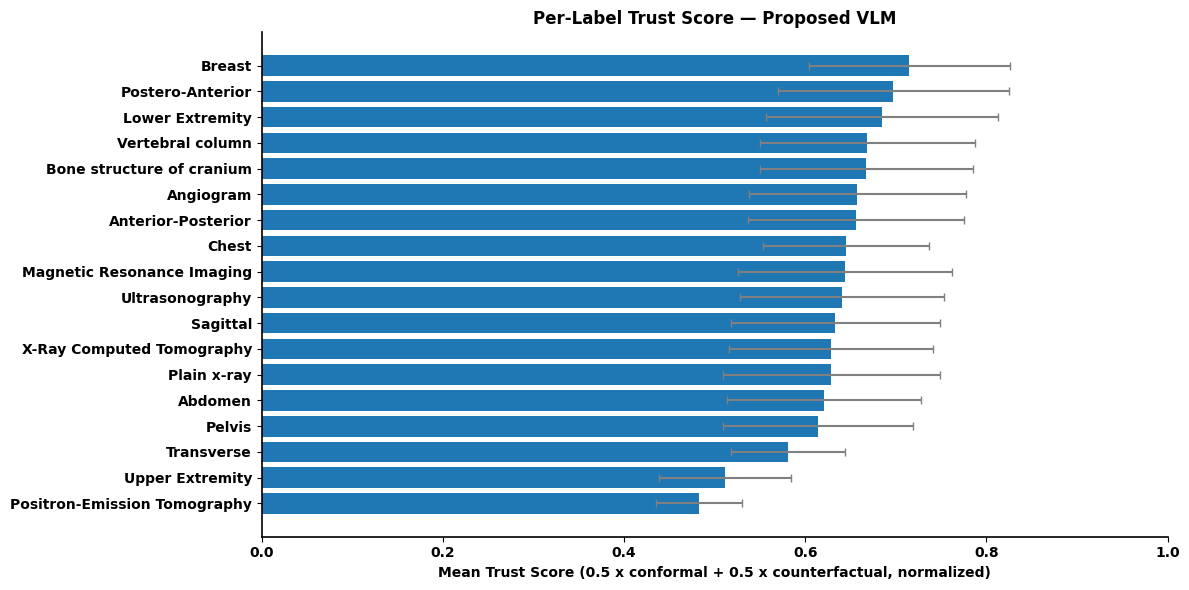

Saved: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/figures/trust_score_by_label.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/figures/trust_score_by_label_300dpi.png


In [ ]:
# ============================================================
# CELL 7 — PER-LABEL TRUST SCORE FIGURE
# ============================================================

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.linewidth": 1.2,
})

fig, ax = plt.subplots(figsize=(12, 6))
plot_df = trust_summary_df.sort_values("Mean_Trust_Score")
ax.barh(plot_df["Label_Name"], plot_df["Mean_Trust_Score"], xerr=plot_df["Std_Trust_Score"],
        color="#1f77b4", ecolor="gray", capsize=3)
ax.set_xlabel("Mean Trust Score (0.5 x conformal + 0.5 x counterfactual, normalized)")
ax.set_title("Per-Label Trust Score — Proposed VLM", fontweight="bold")
ax.set_xlim(0, 1)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(TRUST_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(TRUST_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", TRUST_FIGURE_PDF)
print("Saved:", TRUST_FIGURE_PNG)


## 6. Validation — does Trust Score actually correlate with correctness?

A trust score is only useful if higher scores genuinely correspond to more
reliable predictions. Predictions are binned by Trust Score quintile and
empirical accuracy is measured within each bin — if the score is
meaningful, accuracy should rise monotonically (or close to it) across
bins. Reported honestly either way, not just when it looks good.

In [ ]:
# ============================================================
# CELL 8 — VALIDATION: TRUST SCORE VS. CORRECTNESS
# ============================================================

trust_df["Predicted_Label"] = (trust_df["Original_Prob"] >= 0.5).astype(int)
trust_df["Correct"] = (trust_df["Predicted_Label"] == trust_df["True_Label"]).astype(int)

trust_df["Trust_Score_Bin"] = pd.qcut(trust_df["Trust_Score"], q=N_VALIDATION_BINS, duplicates="drop")

validation_df = (
    trust_df.groupby("Trust_Score_Bin", observed=True)
    .agg(Mean_Trust_Score=("Trust_Score", "mean"), Accuracy=("Correct", "mean"), N=("Correct", "count"))
    .reset_index()
)
safe_save_csv(VALIDATION_PATH, validation_df)
display(validation_df)

spearman_corr = trust_df["Trust_Score"].corr(trust_df["Correct"], method="spearman")
print(f"\nSpearman correlation (Trust Score vs. Correctness): {spearman_corr:.4f}")
if spearman_corr > 0.1:
    print("Positive correlation — higher trust scores are associated with more correct predictions.")
elif spearman_corr < -0.1:
    print("NEGATIVE correlation detected — the trust score is behaving opposite to intended. "
          "Reported honestly; this would need investigation before any trustworthiness claim.")
else:
    print("Weak/no correlation detected — reported honestly; the trust score's practical "
          "usefulness for this model/sample is not strongly demonstrated by this check.")


Saved: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/trust_score_validation_bins.csv


,Trust_Score_Bin,Mean_Trust_Score,Accuracy,N
0,"(0.249, 0.57]",0.424457,0.949444,1800
1,"(0.57, 0.644]",0.617534,0.995556,1800
2,"(0.644, 0.68]",0.662622,0.998889,1800
3,"(0.68, 0.719]",0.698456,1.000000,1800
4,"(0.719, 0.915]",0.757065,1.000000,1800



Spearman correlation (Trust Score vs. Correctness): 0.1659
Positive correlation — higher trust scores are associated with more correct predictions.


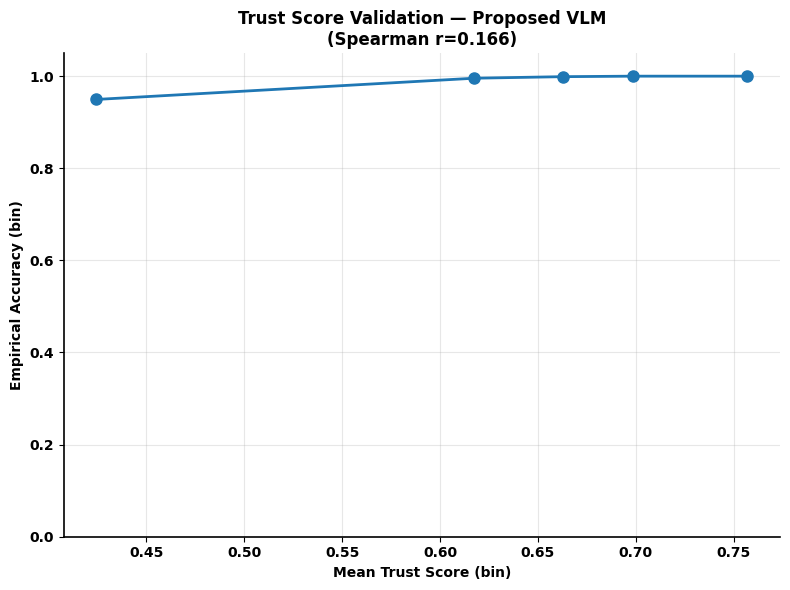

Saved: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/figures/trust_score_validation.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/figures/trust_score_validation_300dpi.png


In [ ]:
# ============================================================
# CELL 9 — VALIDATION FIGURE
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(validation_df["Mean_Trust_Score"], validation_df["Accuracy"], marker="o",
        color="#1f77b4", linewidth=2, markersize=8)
ax.set_xlabel("Mean Trust Score (bin)")
ax.set_ylabel("Empirical Accuracy (bin)")
ax.set_title(f"Trust Score Validation — Proposed VLM\n(Spearman r={spearman_corr:.3f})",
             fontweight="bold")
ax.set_ylim(0, 1.05)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(VALIDATION_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(VALIDATION_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", VALIDATION_FIGURE_PDF)
print("Saved:", VALIDATION_FIGURE_PNG)


## 7. Save configuration and reproducibility record

In [ ]:
# ============================================================
# CELL 10 — SAVE CONFIG AND REPRODUCIBILITY.JSON
# ============================================================

trust_score_config = {
    "scope": "Proposed VLM only",
    "source_samples": "Same 500 Test-final samples x 18 labels analyzed in Notebook 09",
    "formula": "Trust_Score = conformal_weight * conformal_component + counterfactual_weight * counterfactual_component",
    "conformal_weight": CONFORMAL_WEIGHT,
    "counterfactual_weight": COUNTERFACTUAL_WEIGHT,
    "conformal_component_mapping": {"singleton_set": 1.0, "empty_set": 0.5, "both_included_set": 0.0},
    "counterfactual_component": "min-max normalized counterfactual distance (non-converged rows -> 1.0)",
    "validation_method": "Trust-Score-quintile binned accuracy + Spearman correlation vs. correctness",
    "n_validation_bins": N_VALIDATION_BINS,
    "spearman_correlation_trust_vs_correctness": float(spearman_corr),
    "label_names": LABEL_NAMES,
}
safe_save_json(TRUST_CONFIG_PATH, trust_score_config)

reproducibility = {
    "notebook": "11_ROCOv2_Trust_Score",
    "python_version": sys.version, "platform": platform.platform(),
    "numpy_version": np.__version__, "pandas_version": pd.__version__,
    "random_seed": SEED,
    "source_artifacts": {
        "conformal_config": str(CONFORMAL_CONFIG_PATH),
        "counterfactual_results": str(COUNTERFACTUAL_RESULTS_PATH),
    },
}
safe_save_json(REPRODUCIBILITY_PATH, reproducibility)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/trust_score_config.json
Saved: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/reproducibility.json


## 8. Artifact manifest and final report

In [ ]:
# ============================================================
# CELL 11 — ARTIFACT MANIFEST + FINAL REPORT
# ============================================================

artifact_paths = [
    TRUST_SCORES_PATH, TRUST_SUMMARY_PATH, VALIDATION_PATH,
    TRUST_FIGURE_PDF, TRUST_FIGURE_PNG, VALIDATION_FIGURE_PDF, VALIDATION_FIGURE_PNG,
    TRUST_CONFIG_PATH, REPRODUCIBILITY_PATH,
]
manifest = [{
    "Artifact": p.name, "Path": str(p), "Exists": p.exists(),
    "Size_KB": round(p.stat().st_size / 1024, 2) if p.exists() else None,
} for p in artifact_paths]
artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

manifest_missing = [m["Path"] for m in manifest if not m["Exists"]]
notebook_status = "COMPLETE" if not manifest_missing else f"NOT READY — missing: {manifest_missing}"
safe_save_json(MANIFEST_PATH, {"artifacts": manifest, "status": notebook_status})

print("\n" + "=" * 60)
print("ROCOv2 TRUST SCORE")
print("FINAL REPORT")
print("=" * 60)
print(f'''
Model:
Proposed VLM (fine-tuned BiomedCLIP)

Formula:
Trust_Score = {CONFORMAL_WEIGHT} x conformal_component + {COUNTERFACTUAL_WEIGHT} x counterfactual_component

Samples analyzed:
{len(trust_df):,} (sample x label) pairs, 500 Test-final samples x 18 labels

------------------------------------------------------------
VALIDATION
------------------------------------------------------------

Spearman correlation (Trust Score vs. correctness):
{spearman_corr:.4f}

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

Trust Score implemented:
YES (composite of Notebooks 08 and 09's signals, Proposed VLM only)

Model re-trained or re-run:
NO — purely derived from existing artifacts

Previous notebooks modified:
NO

Ready for Evaluation notebook:
{"YES" if not manifest_missing else "NO"}
''')
print("=" * 60)

if notebook_status != "COMPLETE":
    print("\nNOTEBOOK 11 STATUS: NOT READY — see missing artifacts above.")
else:
    print("\nSTOP — Notebook 11 (Trust Score) is complete.")
    print("Next notebook: 12_ROCOv2_Evaluation.ipynb")


,Artifact,Path,Exists,Size_KB
0,trust_scores_per_sample_label.csv,/content/drive/MyDrive/ROCOv2/Prepared/TrustSc...,True,1417.37
1,trust_score_per_label_summary.csv,/content/drive/MyDrive/ROCOv2/Prepared/TrustSc...,True,1.43
2,trust_score_validation_bins.csv,/content/drive/MyDrive/ROCOv2/Prepared/TrustSc...,True,0.30
3,trust_score_by_label.pdf,/content/drive/MyDrive/ROCOv2/Prepared/TrustSc...,True,19.69
4,trust_score_by_label_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/TrustSc...,True,200.81
5,trust_score_validation.pdf,/content/drive/MyDrive/ROCOv2/Prepared/TrustSc...,True,14.70
6,trust_score_validation_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/TrustSc...,True,99.76
7,trust_score_config.json,/content/drive/MyDrive/ROCOv2/Prepared/TrustSc...,True,1.12
8,reproducibility.json,/content/drive/MyDrive/ROCOv2/Prepared/TrustSc...,True,0.51


Saved: /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/artifact_manifest.json

ROCOv2 TRUST SCORE
FINAL REPORT

Model:
Proposed VLM (fine-tuned BiomedCLIP)

Formula:
Trust_Score = 0.5 x conformal_component + 0.5 x counterfactual_component

Samples analyzed:
9,000 (sample x label) pairs, 500 Test-final samples x 18 labels

------------------------------------------------------------
VALIDATION
------------------------------------------------------------

Spearman correlation (Trust Score vs. correctness):
0.1659

------------------------------------------------------------
NOTEBOOK STATUS
------------------------------------------------------------

Trust Score implemented:
YES (composite of Notebooks 08 and 09's signals, Proposed VLM only)

Model re-trained or re-run:
NO — purely derived from existing artifacts

Previous notebooks modified:
NO

Ready for Evaluation notebook:
YES


STOP — Notebook 11 (Trust Score) is complete.
Next notebook: 12_ROCOv2_Evaluation.ipynb
